*Author:*  
Manuel Eugenio Morocho Cayamcela, PhD

# Fetal Health Classification with a Keras Neural Network

Build, monitor, and evaluate a **multiclass** classifier (one-hot encoded labels, softmax output) using the Fetal Health cardiotocography (CTG) dataset.

## Learning goals

- Prepare cardiotocography (CTG) features for modeling.
- One-hot encode a categorical target.
- Train a small Keras network with a softmax output for multiclass classification.
- Inspect learning curves with TensorBoard and use early stopping.
- Optimize the architecture with `keras-tuner`.

The target, `fetal_health`, is categorical: `1` = Normal, `2` = Suspect, `3` = Pathological.

python -c "import tensorflow as tf; print(tf.__version__)"## Contents

## 1. Load and inspect the data

Load `datasets/fetal_health.csv` into a DataFrame and inspect the first rows. The dataset contains CTG-derived features and the categorical `fetal_health` target.

In [1]:
#%pip install -q pandas matplotlib seaborn scikit-learn tensorflow tensorboard keras-tuner

In [2]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)

CLASS_NAMES = ["Normal", "Suspect", "Pathological"]

In [3]:
fetal_df = pd.read_csv("datasets/fetal_health.csv")
fetal_df.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


fetal_health
Normal          0.778457
Suspect         0.138758
Pathological    0.082785
Name: proportion, dtype: float64

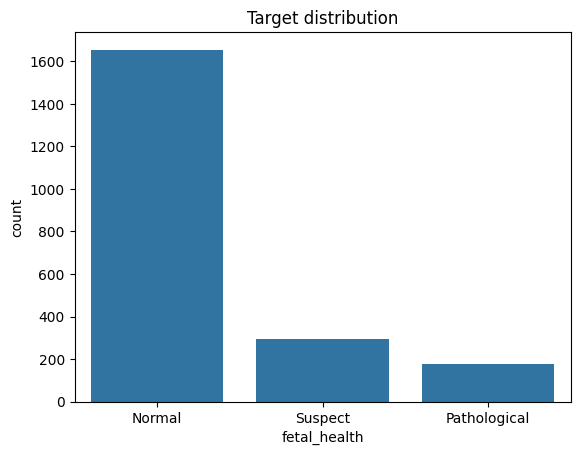

In [4]:
import seaborn as sns

ax = sns.countplot(data=fetal_df, x="fetal_health")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES)
plt.title("Target distribution");

# Relative class frequencies
fetal_df["fetal_health"].value_counts(normalize=True).sort_index().rename(index=dict(zip([1.0, 2.0, 3.0], CLASS_NAMES)))

**Features:** baseline fetal heart rate (FHR), accelerations, fetal movements, uterine contractions, light/severe/prolonged decelerations, short- and long-term variability indices, and descriptors of the FHR histogram (width, min, max, number of peaks and zeroes, mode, mean, median, variance, tendency).

Check the class balance before training. The classes are imbalanced, so accuracy alone is not sufficient; we also report per-class recall and macro-F1.

## 2. Prepare the data

Inspect data types, missing values, and duplicated rows.

In [5]:
fetal_df.info()
print("Missing values:", fetal_df.isna().sum().sum())
print("Duplicated rows:", fetal_df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability  

Remove exact duplicate rows so that the same record cannot appear in both the training and the test set.

In [6]:
fetal_df = fetal_df.drop_duplicates().reset_index(drop=True)
fetal_df.shape

(2113, 22)

#### Outliers

##### Plot the value range of each column

A boxplot summarizes each feature's distribution through its median, quartiles, range, and potential outliers.

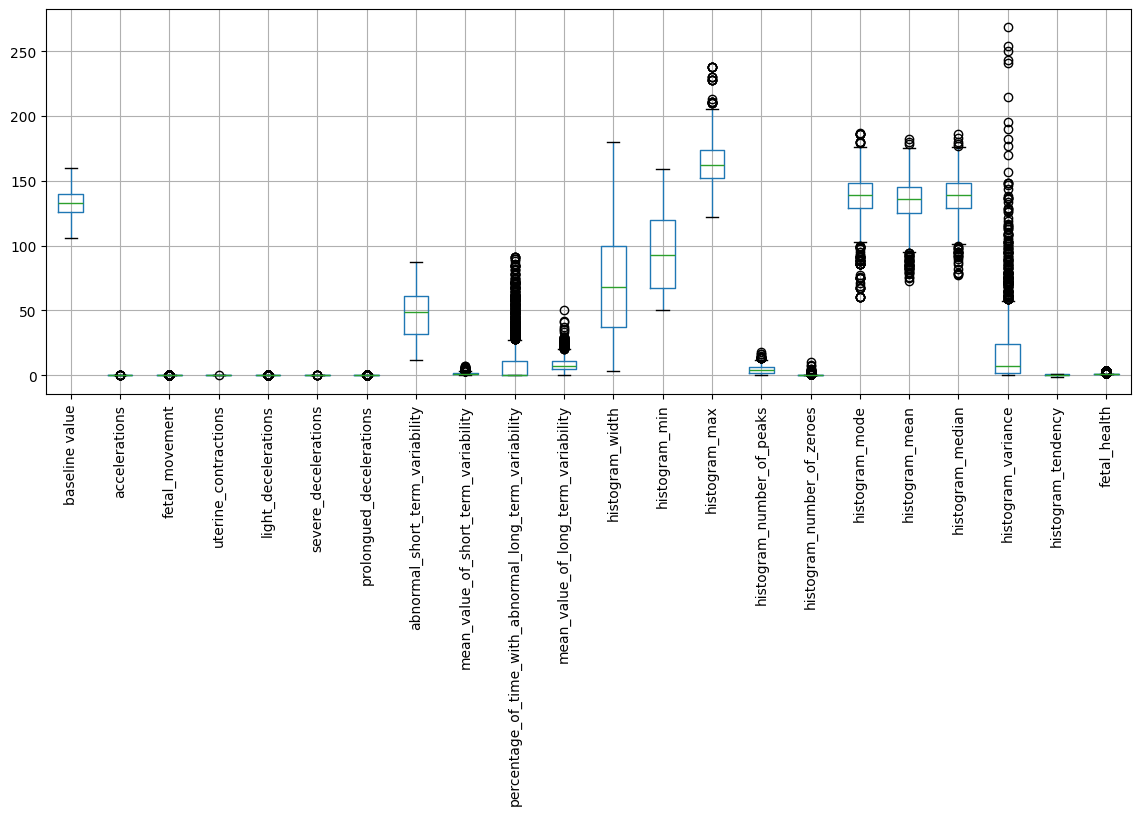

In [7]:
fig, ax = plt.subplots(figsize=(14, 5))
fetal_df.boxplot(ax=ax)
plt.xticks(rotation=90)
plt.show()

Whether to remove outliers depends on the domain. In CTG data, extreme values (e.g., prolonged decelerations, very low variability) are clinically meaningful and often characterize the Pathological class, so we keep them. The very different feature ranges show that scaling is required before training.

#### Zero values

Unlike the diabetes dataset, zeros here are valid measurements (e.g., zero accelerations or zero decelerations in the recording), so they must **not** be replaced with NaN. We only inspect how frequent they are.

In [8]:
zero_share = (fetal_df == 0).mean().sort_values(ascending=False)
zero_share[zero_share > 0]

severe_decelerations                                      0.996687
prolongued_decelerations                                  0.915760
histogram_number_of_zeroes                                0.762423
fetal_movement                                            0.616186
percentage_of_time_with_abnormal_long_term_variability    0.584477
light_decelerations                                       0.576432
histogram_tendency                                        0.525319
accelerations                                             0.419309
uterine_contractions                                      0.152863
histogram_variance                                        0.088027
mean_value_of_long_term_variability                       0.064837
histogram_number_of_peaks                                 0.050639
dtype: float64

#### Impute NaN values with the mean

Imputation statistics must be computed on the **training set only**; otherwise information from the test set leaks into training. The mean imputation is therefore applied after the train/test split (see below). This dataset has no missing values, but the step is kept as a safeguard.

In [9]:
fetal_df.isna().sum().to_frame("missing").T

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
missing,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


#### Plot feature correlations

Use a correlation heatmap to identify linear relationships. Correlation is not causation; weak individual correlations can still be useful in combination.

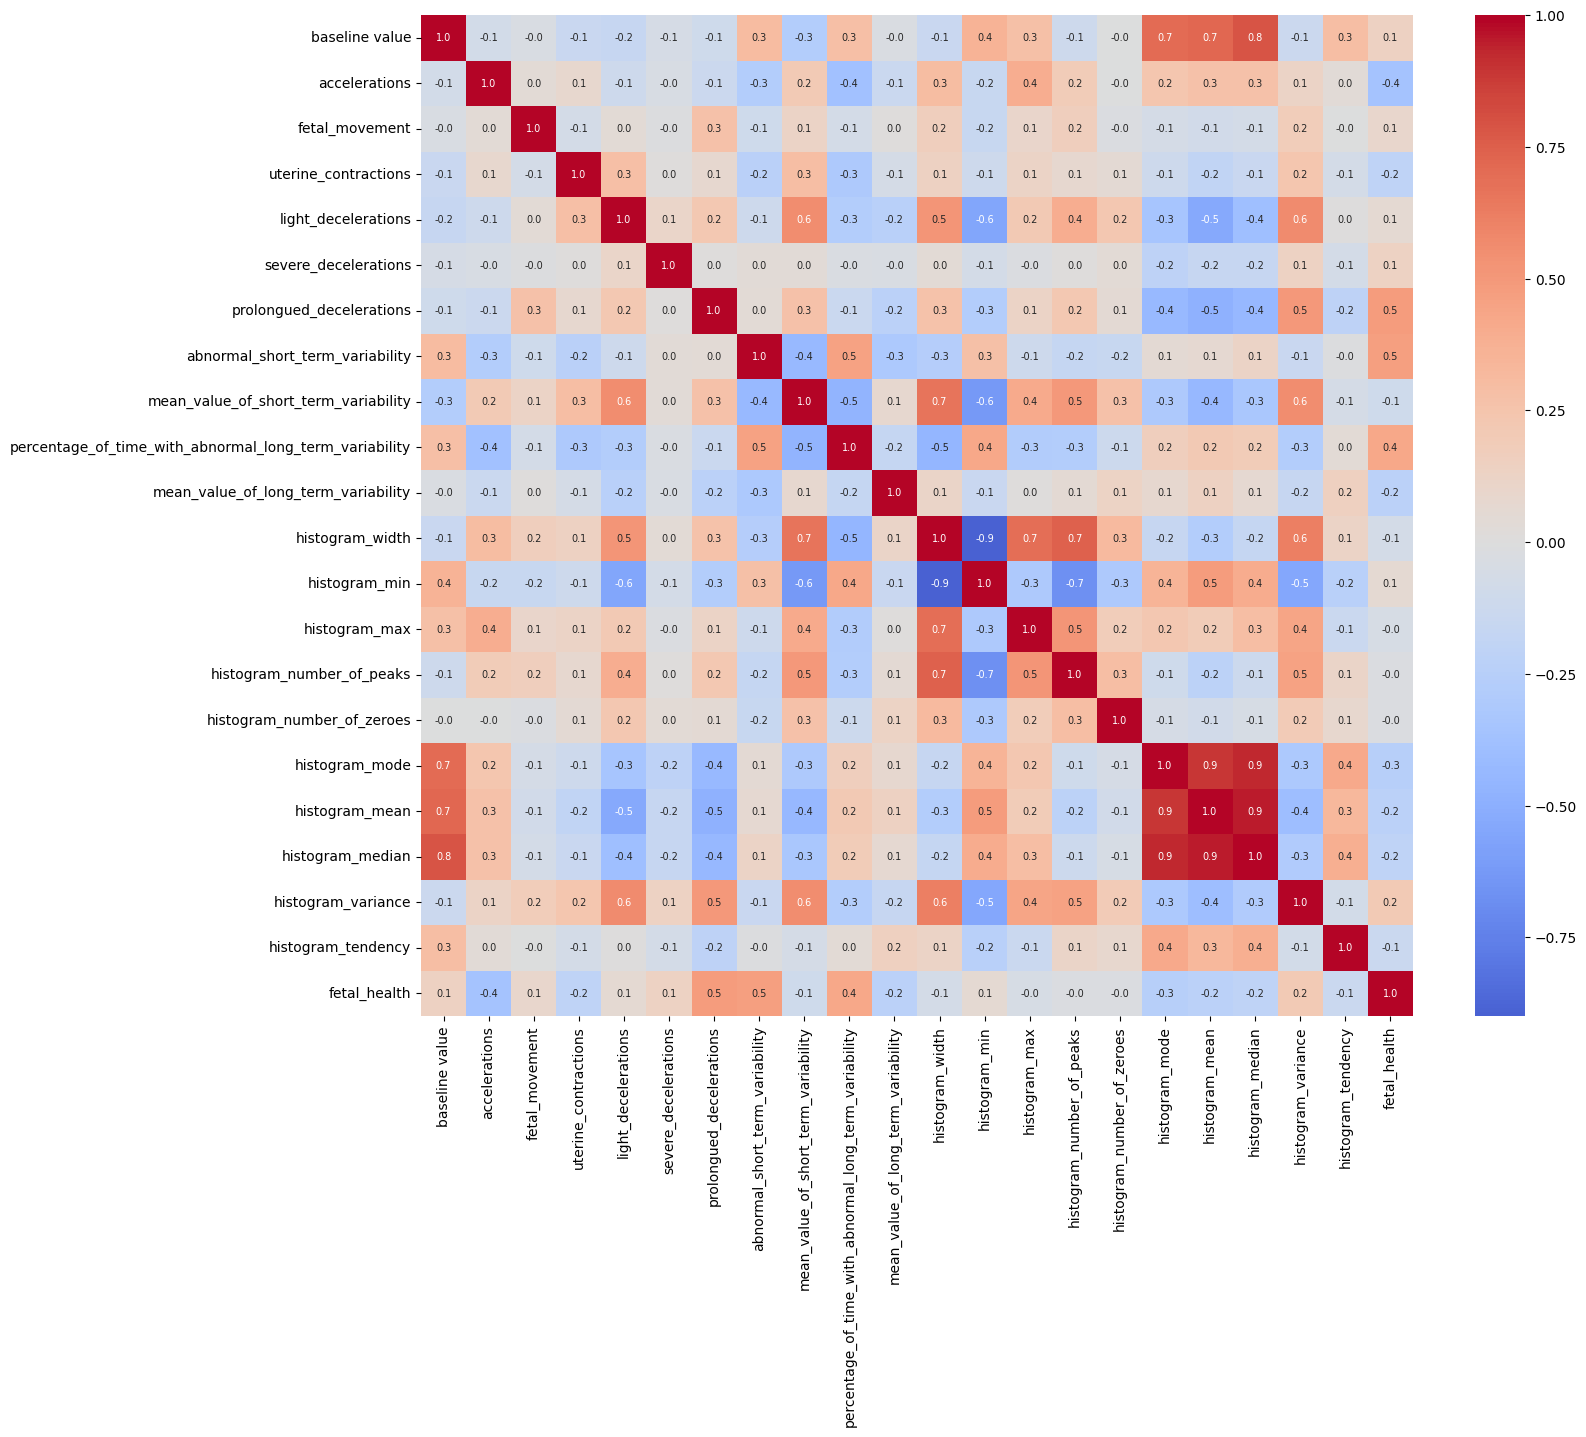

In [10]:
# Plot the correlation matrix
plt.figure(figsize=(16, 13))
sns.heatmap(fetal_df.corr(), annot=True, fmt=".1f", annot_kws={"size": 7}, cmap="coolwarm", center=0)
plt.show()

Correlation analysis describes linear relationships among features and the target. Strong feature-to-feature correlations (e.g., among the histogram mean, median, and mode) indicate redundancy, while weak individual correlations can still help a nonlinear model. Because `fetal_health` is a categorical code, its Pearson correlation with the features is only indicative.

Remember that correlation does not imply causation.

#### Split predictor features `X` and target `y`

Remove the `fetal_health` column to create the predictor matrix `X_fetal`.

In [11]:
X_fetal = fetal_df.drop(columns="fetal_health")
X_fetal.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_width,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0


Select the `fetal_health` column as the target vector `y_fetal` and convert it to integer class indices `0, 1, 2` (Normal, Suspect, Pathological). The integer labels are used for stratification and metrics; the one-hot version is created after the split.

In [12]:
y_fetal = fetal_df["fetal_health"].astype(int) - 1
NUM_CLASSES = y_fetal.nunique()
print("Number of classes:", NUM_CLASSES)
y_fetal.value_counts().sort_index()

Number of classes: 3


fetal_health
0    1646
1     292
2     175
Name: count, dtype: int64

#### Split the data into training and test sets

Use 70% of the data for training and reserve 30% for the final test. Stratification preserves the target class ratio in both sets.

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train_int, y_test_int = train_test_split(
    X_fetal,
    y_fetal,
    test_size=0.3,
    stratify=y_fetal,
    random_state=SEED,
)

#### Impute and scale the features (fit on the training set only)

Feature ranges differ by orders of magnitude (e.g., `histogram_variance` vs. `severe_decelerations`). Standardization (zero mean, unit variance) improves the conditioning of gradient-based optimization. The imputer and the scaler are fit on `X_train` and only applied to `X_test`.

In [14]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="mean").fit(X_train)
scaler = StandardScaler().fit(imputer.transform(X_train))

def preprocess(X):
    return pd.DataFrame(scaler.transform(imputer.transform(X)), columns=X.columns, index=X.index)

X_train = preprocess(X_train)
X_test = preprocess(X_test)
X_train.describe().loc[["mean", "std"]].round(2)

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_width,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency
mean,-0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,...,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


#### One-hot encode the target

With a softmax output of `NUM_CLASSES` units, categorical cross-entropy expects each label as a one-hot vector, e.g. Suspect → `[0, 1, 0]`.

In [15]:
from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train_int, num_classes=NUM_CLASSES)
y_test = to_categorical(y_test_int, num_classes=NUM_CLASSES)

print("Integer labels:", y_train_int.iloc[:5].values)
print("One-hot labels:\n", y_train[:5])

Integer labels: [0 0 2 0 0]
One-hot labels:
 [[1. 0. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [1. 0. 0.]]


## 3. Build and train the neural network

A compact network with ReLU hidden layers and a softmax output predicts the probability of each fetal-health class.

TensorFlow and scikit-learn are installed in the setup cell above. TensorFlow provides the Keras API used to build the neural network.

#### Define a simple neural network

Import `Sequential` to stack layers and `Dense` to create fully connected layers.

In [16]:
# Import the modules used to build the model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

The network has two hidden ReLU layers with 12 and 8 units. A softmax output layer with `NUM_CLASSES` units returns a probability distribution over the classes (non-negative outputs that sum to 1).

In [17]:
# To define the input shape of the model, we need to know the number of features in the training data. The shape of X_train is (number of samples, number of features). By accessing X_train.shape[1], we get the number of features, which will be used as the input dimension for the first layer of the neural network.
X_train.shape[1] 

21

In [18]:
model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    Dense(12, activation="relu"),
    Dense(8, activation="relu"),
    Dense(NUM_CLASSES, activation="softmax"),
])

# Output layer changed from Dense(1, activation="sigmoid")
# to Dense(NUM_CLASSES, activation="softmax")

#### Compile the neural network

Compile with Adam, categorical cross-entropy, and accuracy. Categorical cross-entropy matches one-hot labels and a softmax output. With `binary_crossentropy` the code would still run, but Keras would compute *binary* accuracy element-wise over the one-hot vector, which inflates accuracy when there are more than two classes.

In [19]:
# Compile with Adam, categorical cross-entropy, and accuracy
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

#### Inspect the neural-network summary

`model.summary()` displays each layer, its output shape, and its trainable parameters.

In [20]:
# Display the model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 395 (1.54 KB)

 Trainable params: 395 (1.54 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Display the model output shape
model.output_shape

(None, 3)

#### Train the neural network

`model.fit()` learns from the training examples. An epoch is one pass through the training set; `batch_size` controls how many examples are processed before each weight update.

#### Train with early stopping to reduce overfitting

In [22]:
log_dir = Path("logs/fit") / ("baseline-" + datetime.now().strftime("%Y%m%d-%H%M%S"))
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True
    ),
    tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1),
]

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)
print(f"TensorBoard logs written to: {log_dir}")

Epoch 1/200
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.2663 - loss: 1.2732 - val_accuracy: 0.4696 - val_loss: 1.0790
Epoch 2/200
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6086 - loss: 0.9464 - val_accuracy: 0.6486 - val_loss: 0.8732
Epoch 3/200
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7557 - loss: 0.7634 - val_accuracy: 0.7365 - val_loss: 0.7407
Epoch 4/200
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8191 - loss: 0.6365 - val_accuracy: 0.7669 - val_loss: 0.6416
Epoch 5/200
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8453 - loss: 0.5372 - val_accuracy: 0.7838 - val_loss: 0.5626
Epoch 6/200
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8588 - loss: 0.4569 - val_accuracy: 0.7973 - val_loss: 0.5020
Epoch 7/200
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8690 - loss: 0.3961 - val_accuracy: 0.8108 - val_loss: 0.4579
Epoch 8/200
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8800 - loss: 0.3551 - val_accuracy: 0.8243 - 

In [23]:
%load_ext tensorboard

In [24]:
import os, sys
os.environ["TENSORBOARD_BINARY"] = os.path.join(sys.prefix, "Scripts", "tensorboard.exe")
%tensorboard --logdir logs/fit # Make sure to run this command in the specific folder where the logs are stored. You can also specify a different log directory if you have set it up differently in the code above.

## 4. Evaluate the model

Evaluate loss and accuracy on both the training and test sets. Compare the results to check for potential overfitting. Because the classes are imbalanced, also inspect per-class precision/recall, macro-F1, and the confusion matrix.

In [25]:
# Evaluate on the training data
scores = model.evaluate(X_train, y_train, verbose=False)
print("Training accuracy: %.2f%%" % (scores[1] * 100))

# Evaluate on the test data
scores = model.evaluate(X_test, y_test, verbose=False)
print("Test accuracy: %.2f%%" % (scores[1] * 100))

Training accuracy: 90.33%
Test accuracy: 87.38%


--- Baseline ---
              precision    recall  f1-score   support

      Normal      0.915     0.957     0.936       494
     Suspect      0.623     0.545     0.582        88
Pathological      0.825     0.635     0.717        52

    accuracy                          0.874       634
   macro avg      0.788     0.713     0.745       634
weighted avg      0.867     0.874     0.869       634



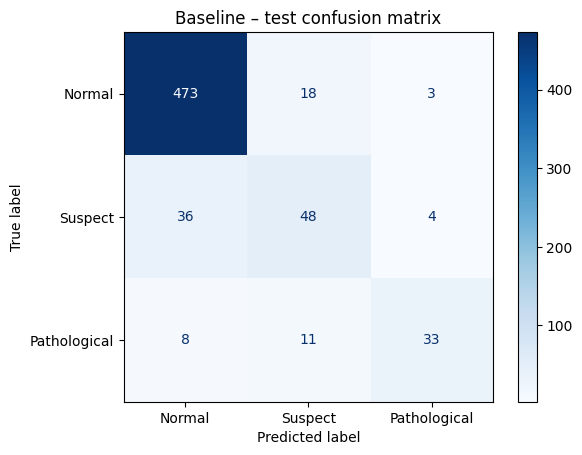

In [26]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, balanced_accuracy_score)

def evaluate_classifier(clf, name):
    """Report test metrics and return a summary row for the comparison table."""
    y_pred_int = clf.predict(X_test, verbose=0).argmax(axis=1)
    print(f"--- {name} ---")
    print(classification_report(y_test_int, y_pred_int, target_names=CLASS_NAMES, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y_test_int, y_pred_int),
                           display_labels=CLASS_NAMES).plot(cmap="Blues")
    plt.title(f"{name} – test confusion matrix")
    plt.show()
    train_loss, train_acc = clf.evaluate(X_train, y_train, verbose=0)[:2]
    test_loss, test_acc = clf.evaluate(X_test, y_test, verbose=0)[:2]
    return {
        "model": name,
        "parameters": clf.count_params(),
        "train_accuracy": train_acc,
        "test_accuracy": test_acc,
        "train_test_gap": train_acc - test_acc,
        "test_loss": test_loss,
        "test_balanced_accuracy": balanced_accuracy_score(y_test_int, y_pred_int),
        "test_macro_f1": f1_score(y_test_int, y_pred_int, average="macro"),
        "test_weighted_f1": f1_score(y_test_int, y_pred_int, average="weighted"),
    }

baseline_results = evaluate_classifier(model, "Baseline")

## 5. Make a prediction

Select one example from the test set. `iloc[10]` returns its eleventh row.

In [27]:
# Select a CTG record from the test set for prediction
registro_de_prueba = X_test.iloc[10]
registro_de_prueba

baseline value                                           -0.829338
accelerations                                             0.201073
fetal_movement                                            0.034273
uterine_contractions                                      0.221417
light_decelerations                                       1.430360
severe_decelerations                                     -0.063823
prolongued_decelerations                                 -0.280097
abnormal_short_term_variability                          -1.387711
mean_value_of_short_term_variability                      0.960094
percentage_of_time_with_abnormal_long_term_variability   -0.537200
mean_value_of_long_term_variability                      -0.132218
histogram_width                                           1.413347
histogram_min                                            -1.379239
histogram_max                                             0.794044
histogram_number_of_peaks                                 1.36

Keras expects a two-dimensional input. Reshape the selected row into one sample with `X_train.shape[1]` features before calling `predict()`.

In [28]:
# Predict with the trained model
prediccion = model.predict(registro_de_prueba.values.reshape(1, -1))
prediccion

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


array([[9.9677449e-01, 2.3461457e-03, 8.7926787e-04]], dtype=float32)

The softmax output is a probability vector over the three classes. The predicted class is the one with the highest probability (`argmax`), which replaces the 0.5 threshold of the binary case. Then compare that class with the known test label.

In [29]:
# Classify the model prediction
clase_predicha = int(np.argmax(prediccion, axis=1)[0])
print(f'Neural-network prediction: {CLASS_NAMES[clase_predicha]} (p = {prediccion[0, clase_predicha]:.3f})')

# Display the true test label
clase_real = int(y_test_int.iloc[10])
print(f'Test dataset label: {CLASS_NAMES[clase_real]}')

Neural-network prediction: Normal (p = 0.997)
Test dataset label: Normal


## 6. Save and reload the model

In [30]:
# Save the model to a file
model.save('modelo_fetal_health.keras')

# The imputer and scaler are part of the model pipeline: new data must be
# transformed with the same training statistics before calling predict()
import joblib
joblib.dump({"imputer": imputer, "scaler": scaler}, 'preprocesamiento_fetal_health.joblib')

['preprocesamiento_fetal_health.joblib']

In [31]:
# Load the model from the file
from tensorflow.keras.models import load_model
modelo_cargado = load_model('modelo_fetal_health.keras')

In [32]:
# Predict with the reloaded model
prediccion_modelo_cargado = modelo_cargado.predict(registro_de_prueba.values.reshape(1, -1))

# Classify the reloaded-model prediction
clase_cargado = int(np.argmax(prediccion_modelo_cargado, axis=1)[0])
print(f'Reloaded-model prediction: {CLASS_NAMES[clase_cargado]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Reloaded-model prediction: Normal


## Activity: Optimize the neural-network architecture

### Goal
Work in groups to improve the fetal-health classifier through hyperparameter search.

### Instructions

1. Form a group of 2 or work individually.
2. Search for a new dataset
3. Buils a neural network and use `keras-tuner`, or `optuna` to search for the best hyperparameters.
4. Evaluate the best model and report the results.

## 7. Hyperparameter search with `keras-tuner`

**Method: Hyperband.** Hyperband samples many random configurations, trains them for a few epochs, and repeatedly keeps only the best `1/factor` fraction, which then receive `factor`× more epochs (successive halving across several brackets). This allocates the compute budget to promising configurations instead of training every candidate to convergence.

**Objective:** validation macro-F1 (`val_f1_macro`), because accuracy is dominated by the majority class (Normal).

**Search space:**

| Hyperparameter | Range |
|---|---|
| Number of hidden layers | 1 – 3 |
| Units per hidden layer | 8 – 128 (step 8) |
| Activation | ReLU, tanh |
| Dropout per hidden layer | 0.0 – 0.5 (step 0.1) |
| Learning rate (Adam) | 1e-4 – 1e-2 (log scale) |
| Batch size | 16, 32, 64 |

The output layer is fixed: `Dense(NUM_CLASSES, activation="softmax")` with categorical cross-entropy.

In [33]:
import keras_tuner as kt
from tensorflow.keras.layers import Dropout

class FetalHyperModel(kt.HyperModel):
    def build(self, hp):
        model = Sequential()
        model.add(tf.keras.Input(shape=(X_train.shape[1],)))
        activation = hp.Choice("activation", ["relu", "tanh"])
        for i in range(hp.Int("num_layers", 1, 3)):
            model.add(Dense(hp.Int(f"units_{i}", 8, 128, step=8), activation=activation))
            model.add(Dropout(hp.Float(f"dropout_{i}", 0.0, 0.5, step=0.1)))
        model.add(Dense(NUM_CLASSES, activation="softmax"))
        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=hp.Float("learning_rate", 1e-4, 1e-2, sampling="log")
            ),
            loss="categorical_crossentropy",
            metrics=["accuracy", tf.keras.metrics.F1Score(average="macro", name="f1_macro")],
        )
        return model

    def fit(self, hp, model, *args, **kwargs):
        # Batch size is a training hyperparameter, so it is tuned here
        return model.fit(*args, batch_size=hp.Choice("batch_size", [16, 32, 64]), **kwargs)

tuner = kt.Hyperband(
    FetalHyperModel(),
    objective=kt.Objective("val_f1_macro", direction="max"),
    max_epochs=81,
    factor=3,
    seed=SEED,
    directory="kt_logs",
    project_name="fetal_health_hyperband",
    overwrite=True,
)
tuner.search_space_summary()

Search space summary
Default search space size: 5
activation (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh'], 'ordered': False}
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 8, 'max_value': 128, 'step': 8, 'sampling': 'linear'}
dropout_0 (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}


Run the search. The same validation scheme as the baseline (`validation_split=0.2`) is used, and early stopping ends unpromising trials.

In [34]:
tuner.search(
    X_train,
    y_train,
    validation_split=0.2,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10)],
    verbose=1,
)
tuner.results_summary(num_trials=5)

Trial 211 Complete [00h 00m 10s]
val_f1_macro: 0.8110451698303223

Best val_f1_macro So Far: 0.862666666507721
Total elapsed time: 00h 10m 45s
Results summary
Results in kt_logs\fetal_health_hyperband
Showing 5 best trials
Objective(name="val_f1_macro", direction="max")

Trial 0193 summary
Hyperparameters:
activation: tanh
num_layers: 2
units_0: 128
dropout_0: 0.2
learning_rate: 0.007435938698470362
batch_size: 32
units_1: 32
dropout_1: 0.0
units_2: 56
dropout_2: 0.1
tuner/epochs: 81
tuner/initial_epoch: 27
tuner/bracket: 2
tuner/round: 2
tuner/trial_id: 0188
Score: 0.862666666507721

Trial 0188 summary
Hyperparameters:
activation: tanh
num_layers: 2
units_0: 128
dropout_0: 0.2
learning_rate: 0.007435938698470362
batch_size: 32
units_1: 32
dropout_1: 0.0
units_2: 56
dropout_2: 0.1
tuner/epochs: 27
tuner/initial_epoch: 9
tuner/bracket: 2
tuner/round: 1
tuner/trial_id: 0187
Score: 0.8362371325492859

Trial 0172 summary
Hyperparameters:
activation: tanh
num_layers: 1
units_0: 112
dropout_

#### Best hyperparameters

Only the hyperparameters active in the best configuration are shown (units and dropout of unused layers are omitted).

In [35]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

best_config = {
    "num_layers": best_hp.get("num_layers"),
    "activation": best_hp.get("activation"),
    "learning_rate": best_hp.get("learning_rate"),
    "batch_size": best_hp.get("batch_size"),
}
for i in range(best_hp.get("num_layers")):
    best_config[f"units_{i}"] = best_hp.get(f"units_{i}")
    best_config[f"dropout_{i}"] = best_hp.get(f"dropout_{i}")

pd.Series(best_config, name="best value").to_frame()

,best value
num_layers,2
activation,tanh
learning_rate,0.007436
batch_size,32
units_0,128
dropout_0,0.2
units_1,32
dropout_1,0.0


#### Retrain the best configuration

Retrain the best configuration with the same protocol as the baseline (validation split, 200 epochs maximum, early stopping on `val_loss` with patience 20), logging to TensorBoard for comparison.

In [36]:
hypermodel = FetalHyperModel()
best_model = hypermodel.build(best_hp)
best_model.summary()

log_dir_tuned = Path("logs/fit") / ("tuned-" + datetime.now().strftime("%Y%m%d-%H%M%S"))
history_tuned = hypermodel.fit(
    best_hp,
    best_model,
    X_train,
    y_train,
    validation_split=0.2,
    epochs=200,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
        tf.keras.callbacks.TensorBoard(log_dir=log_dir_tuned, histogram_freq=1),
    ],
    verbose=0,
)
print(f"Epochs trained: {len(history_tuned.history['loss'])}")
print(f"TensorBoard logs written to: {log_dir_tuned}")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,043 (27.51 KB)

 Trainable params: 7,043 (27.51 KB)

 Non-trainable params: 0 (0.00 B)

Epochs trained: 35
TensorBoard logs written to: logs\fit\tuned-20261110-201909


#### Evaluate the optimized network and compare with the baseline

--- Tuned (Hyperband) ---
              precision    recall  f1-score   support

      Normal      0.930     0.964     0.946       494
     Suspect      0.729     0.580     0.646        88
Pathological      0.827     0.827     0.827        52

    accuracy                          0.899       634
   macro avg      0.828     0.790     0.806       634
weighted avg      0.893     0.899     0.895       634



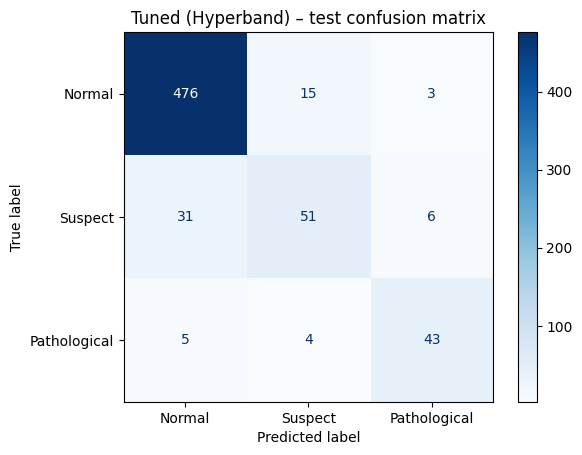

model,Baseline,Tuned (Hyperband),difference
parameters,395.0000,7043.0000,6648.0000
train_accuracy,0.9033,0.9344,0.0311
test_accuracy,0.8738,0.8991,0.0252
train_test_gap,0.0295,0.0354,0.0059
test_loss,0.2910,0.2424,-0.0487
test_balanced_accuracy,0.7125,0.7900,0.0775
test_macro_f1,0.7450,0.8063,0.0613
test_weighted_f1,0.8687,0.8948,0.0261


In [37]:
tuned_results = evaluate_classifier(best_model, "Tuned (Hyperband)")

comparison = pd.DataFrame([baseline_results, tuned_results]).set_index("model").T
comparison["difference"] = comparison.iloc[:, 1] - comparison.iloc[:, 0]
comparison.round(4)

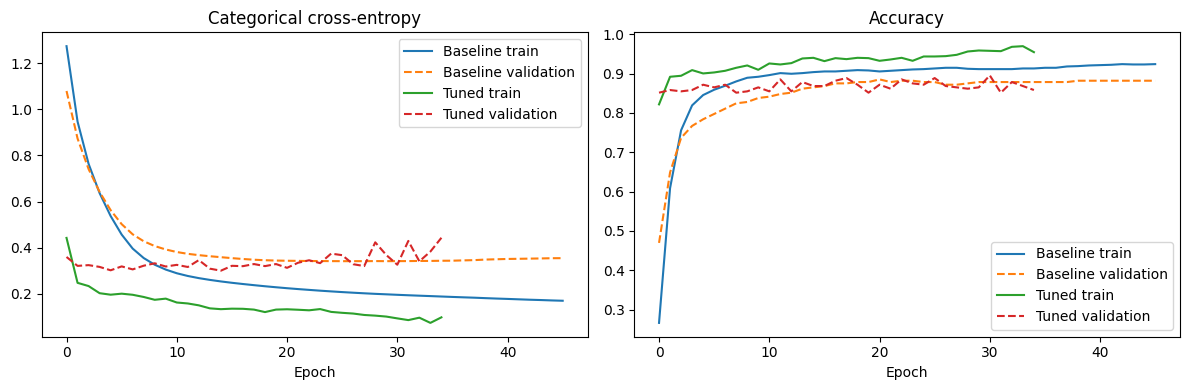

In [38]:
# Learning curves: baseline vs. tuned network
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for h, label in [(history, "Baseline"), (history_tuned, "Tuned")]:
    axes[0].plot(h.history["loss"], label=f"{label} train")
    axes[0].plot(h.history["val_loss"], "--", label=f"{label} validation")
    axes[1].plot(h.history["accuracy"], label=f"{label} train")
    axes[1].plot(h.history["val_accuracy"], "--", label=f"{label} validation")
axes[0].set(title="Categorical cross-entropy", xlabel="Epoch")
axes[1].set(title="Accuracy", xlabel="Epoch")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

a. Which hyperparameter search method did you use?
- **Hyperband** (`keras_tuner.Hyperband`, `max_epochs=81`, `factor=3`): 5 brackets, 211 trials, 10 min 45 s on CPU. Hyperband trains many random configurations for a few epochs and repeatedly promotes the best third with 3× more epochs (successive halving), concentrating compute on promising candidates.
- Objective: **validation macro-F1** (`val_f1_macro`) instead of accuracy, because the classes are imbalanced (77.8% Normal, 13.9% Suspect, 8.3% Pathological). Early stopping (`val_loss`, patience 10) ended unpromising trials.

b. Which parameters did you search?
- Number of hidden layers: 1–3
- Units per hidden layer: 8–128 (step 8)
- Activation: ReLU, tanh
- Dropout per hidden layer: 0.0–0.5 (step 0.1)
- Adam learning rate: 1e-4–1e-2 (log scale)
- Batch size: 16, 32, 64
- Fixed: softmax output with 3 units (one-hot labels) and categorical cross-entropy.
- **Best configuration:** 2 tanh layers (128–32 units), dropout 0.2/0.0, learning rate ≈ 7.4e-3, batch size 32 (7,043 parameters vs. 395 in the baseline).

c. How do the optimized network metrics compare with the baseline network?

| Test metric | Baseline | Tuned | Δ |
|---|---|---|---|
| Accuracy | 0.874 | 0.899 | +0.025 |
| Macro-F1 | 0.745 | 0.806 | +0.061 |
| Balanced accuracy | 0.713 | 0.790 | +0.077 |
| Loss | 0.291 | 0.242 | −0.049 |
| Recall – Suspect | 0.545 | 0.580 | +0.034 |
| Recall – Pathological | 0.635 | 0.827 | +0.192 |
| Train–test accuracy gap | 0.030 | 0.035 | +0.006 |

- The tuned network improves every test metric. The largest gains are in the minority classes, which accuracy alone hides: Pathological recall rises from 33/52 to 43/52, and Pathological cases predicted as Normal (the most critical error) drop from 8 to 5.
- Suspect remains the weakest class: 31 of 88 Suspect cases are still predicted as Normal, although Suspect precision improves the most (0.623 → 0.729).
- The train–test gap increases slightly (3.0 → 3.5 pp). The learning curves show the tuned validation loss rising after epoch ~15 while the training loss keeps decreasing; early stopping restored the weights of epoch 15 (training stopped at epoch 35).
- Caveats: the best validation macro-F1 (0.863) exceeds the test value (0.806), an optimistic bias from selecting the best of 211 trials on a small validation set (~296 samples). In a previous run, the search selected a different architecture (3 ReLU layers) and reached almost the same test macro-F1 (0.807), so the result is a performance plateau rather than one unique optimal architecture. Results come from a single train/test split, and the minority-class gains correspond to a few cases, so they should be confirmed with repeated evaluation.

d. What else would you try to improve the metrics or reduce overfitting?
- **Class imbalance:** use `class_weight` or oversampling (e.g., SMOTE on the training set only), and tune the decision rule to favor recall of Suspect and Pathological.
- **More reliable evaluation:** stratified k-fold cross-validation with several seeds (report mean ± SD), instead of the unstratified `validation_split`, a paired test (McNemar) between models, and `tf.config.experimental.enable_op_determinism()` for run-to-run reproducibility.
- **Search space:** three of the four distinct top configurations chose learning rates above 0.007, close to the 1e-2 upper bound, so widen the range or add a scheduler (`ReduceLROnPlateau`); try Bayesian optimization or more Hyperband iterations.
- **Regularization:** L2 weight decay and batch normalization, or penalize model size, since the tuned network uses 17.8× more parameters.
- **Features and benchmark:** remove redundant, highly correlated histogram features (mean, median, mode), and compare against a gradient-boosting model, a strong baseline for tabular data.